In [28]:
import time
import h5py
import importlib
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/')

from chemrixs.average import Average
from chemrixs.smalldata import SmallData
from chemrixs.process import Reduced
from chemrixs.utils import *
import chemrixs.utils 
importlib.reload(chemrixs.utils)
from pathlib import Path
%matplotlib widget 

In [30]:

# synthetic waveform: flat baseline then a clean negative dip
def make_fake_waveform(n_shots=10, n_channels=4, n_samples=100, 
                        dip_start=40, dip_end=60, dip_depth=-1.0,
                        noise=0.01):
    wf = np.random.normal(0, noise, (n_shots, n_channels, n_samples))
    wf[:, :, dip_start:dip_end] += dip_depth
    return wf

wf = make_fake_waveform()

# case 1: auto_roi=True, channels='all' — should accept all 4 channels
cfg_all = {'channels': 'all', 'roi': [[0,0]]*4, 'bg_roi': [0,30], 'auto_roi': True}
resolved = resolve_rois(cfg_all, wf)
print(resolved['channels'])   # expect [0, 1, 2, 3]
print(resolved['roi'])        # expect ~[[39.x, 60.x]] for each
print(resolved['bg_roi'])     # expect [0, 30] — unchanged

# case 2: auto_roi=True, channels=[0,1] — should restrict to those two
cfg_subset = {'channels': [0,1], 'roi': [[0,0]]*4, 'bg_roi': [0,30], 'auto_roi': True}
resolved = resolve_rois(cfg_subset, wf)
print(resolved['channels'])   # expect [0, 1]

# case 3: auto_roi=False — should pass YAML values straight through untouched
cfg_manual = {'channels': [2,3], 'roi': [[65,75],[65,75]], 'bg_roi': [0,30], 'auto_roi': False}
resolved = resolve_rois(cfg_manual, wf)
print(resolved['channels'])   # expect [2, 3]
print(resolved['roi'])        # expect [[65,75],[65,75]]

# case 4: fallback — no valid channels (all positive dips should be rejected)
wf_pos = make_fake_waveform(dip_depth=+1.0)   # positive excursion -> rejected
cfg_fallback = {'channels': 'all', 'roi': [[65,75]]*4, 'bg_roi': [0,30], 'auto_roi': True}
resolved = resolve_rois(cfg_fallback, wf_pos)
print(resolved['roi'])        # expect [[65,75],...] — fallback to YAML

DEBUG _channel_rois returning: [38, 60], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [38, 60], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [39, 60], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [36, 61], types: <class 'int'>, <class 'int'>
[0, 1, 2, 3]
[[38, 60], [38, 60], [39, 60], [36, 61]]
[0, 30]
DEBUG _channel_rois returning: [38, 60], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [38, 60], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [39, 60], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [36, 61], types: <class 'int'>, <class 'int'>
[0, 1]
[2, 3]
[[65, 75], [65, 75]]
[[65, 75], [65, 75], [65, 75], [65, 75]]


/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/chemrixs/utils.py:125: RuntimeWarning: auto_roi found no valid signal ROIs — falling back to manual values.
  warnings.warn(


In [29]:
wf = make_fake_waveform()
cfg = {'channels': 'all', 'roi': [[0,0]]*4, 'bg_roi': [0,30], 'auto_roi': True}
resolved = resolve_rois(cfg, wf)

# sanity checks before passing downstream
assert len(resolved['channels']) == len(resolved['roi']), \
    "channels and roi lists must be the same length"
assert all(len(r) == 2 for r in resolved['roi']), \
    "each roi entry must be [start, end]"
assert resolved['roi'] != [[0.0, 0.0]] * len(resolved['channels']), \
    "roi should not be all zeros after auto-detection"
    
print(type(resolved['roi']))
print(resolved['roi'])
print(type(resolved['roi'][0]))
print(type(resolved['roi'][0][0]))
print(resolved['channels'])

result = sumchan_helper(wf, resolved)
print(result.shape)    # expect (n_shots,)
assert not np.all(result == 0), "sum should be nonzero for a real signal"

DEBUG _channel_rois returning: [39, 63], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [39, 60], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [39, 60], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [39, 60], types: <class 'int'>, <class 'int'>
<class 'list'>
[[39, 63], [39, 60], [39, 60], [39, 60]]
<class 'list'>
<class 'int'>
[0, 1, 2, 3]
(10,)


/sdf/data/lcls/ds/rix//rix101231825/hdf5/smalldata/rix101231825_Run0112.h5
<KeysViewHDF5 ['c_atmopal_calib', 'c_piranha_calib', 'det_crix_w8_calib', 'det_rix_fim0_calib', 'det_rix_fim1_calib', 'fzp_piranha_calib']>
<KeysViewHDF5 ['axis_svls', 'timestamp']>
fim0 shape: (28908, 8, 256), fim1 shape: (28908, 8, 256)
DEBUG _channel_rois returning: [62, 67], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [61, 67], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [57, 67], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [59, 67], types: <class 'int'>, <class 'int'>
DEBUG _channel_rois returning: [61, 66], types: <class 'int'>, <class 'int'>


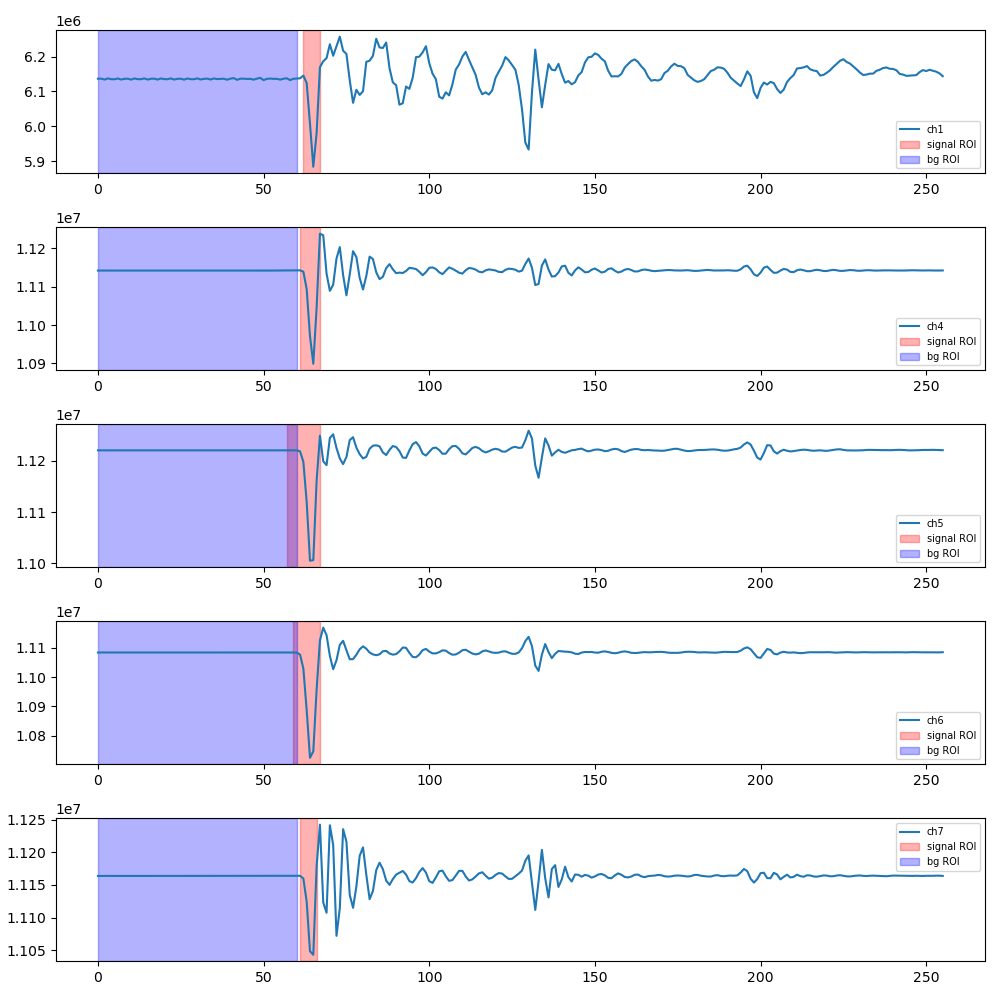

In [33]:
import yaml
# --- config ---
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 112 
fyaml_path = '../roi_input.yml'         # swap to ferufe/roi_input_ferufe.yml if needed
n_show     = -1                       # subsample for speed
fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'

with open(fyaml_path) as f:
    cfg = yaml.safe_load(f)
fim0_cfg = cfg['fim0']; fim1_cfg = cfg['fim1']

print(fname)


with h5py.File(fname, 'r') as h5:
    print(h5['Sums'].keys())
    print(h5['intg'].keys())
    fim0_wf = h5['intg']['axis_svls']['det_rix_fim0_sum_full_area'][:n_show]   # (shots, channels, samples)
    fim1_wf = h5['intg']['axis_svls']['det_rix_fim1_sum_full_area'][:n_show]
    print(f'fim0 shape: {fim0_wf.shape}, fim1 shape: {fim1_wf.shape}')
    
    
# load a small real slice however you normally would
wf_real = fim1_wf   # shape (shots, channels, samples)

cfg_real = {'channels': 'all', 'roi': [[65,75]]*8, 'bg_roi': [0,60], 'auto_roi': True, 'verbose': True}
resolved = resolve_rois(cfg_real, wf_real)

# plot template with detected ROIs overlaid to verify by eye
import matplotlib.pyplot as plt
template = wf_real.mean(axis=0)   # (channels, samples)

fig, axes = plt.subplots(len(resolved['channels']), 1, figsize=(10, 2*len(resolved['channels'])))
for i, ch in enumerate(resolved['channels']):
    axes[i].plot(template[ch], label=f'ch{ch}')
    s, e = resolved['roi'][i]
    axes[i].axvspan(s, e, alpha=0.3, color='red', label='signal ROI')
    bs, be = resolved['bg_roi']
    axes[i].axvspan(bs, be, alpha=0.3, color='blue', label='bg ROI')
    axes[i].legend(fontsize=7)
plt.tight_layout()
plt.show()